# Chen et al. 2021 — Prostate Cancer (10x)
## 01 · Preprocessing → Gate 1 (integration + continuity)

Malignant-only re-analysis. Load → per-sample threshold (gap-derived) → overdispersed genes → PCA → Harmony on `sample` → **integration-strength (θ) × n_pcs sweep judged with a per-neighborhood iLISI** (never a single scalar) → UMAP → radius-graph island removal → cell-cycle/lobe check → **Gate 1**.

Outputs written to the `Chen2021_Prostate-1` roots; raw input is read from `Data_Chen2021_Prostate`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'   # scFates PPT -> rpy2 -> r-mgcv (conda R)
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# paths — cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset-1>
name = os.path.basename(os.getcwd())                      # 'Chen2021_Prostate-1' (output name, -1 suffixed)
cat  = os.path.basename(os.path.dirname(os.getcwd()))     # 'Prostate'
dset = name[:-2] if name.endswith('-1') else name         # 'Chen2021_Prostate' (raw input name)
pth  = os.path.join(*([os.pardir]*6))                     # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                            # raw
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)        # h5ads (-1)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # figures (-1)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', dset, '| category:', cat, '| output dir:', name)

dataset: Chen2021_Prostate | category: Prostate | output dir: Chen2021_Prostate-1


### Load malignant cells
The loader auto-detects normalization from the matrix filename (`UMIcounts` → `normalize_total`), always `log1p`. This 3CA export is malignant-only; every cell carries the study's precomputed cell-cycle scores/phase and meta-programs (`mp_top`).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())
print('cell_cycle_phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Chen2021_Prostate
Done.
full atlas: (36424, 25044)
malignant: (14291, 25044) | samples: 13
expression: X max 7.90 (log1p of normalize_total counts)
cell_cycle_phase: {'Not cycling': 13384, 'G2/M': 161, 'G1/S': 116, 'Intermediate': 18}


### Per-sample threshold — derived from the count gap (C1/C2)
Sort per-sample malignant counts; the largest multiplicative gap marks under-populated samples. Threshold = geometric mean across that gap (not the inherited `≥100` constant).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [4814 1876 1723 1486 1109 1052  595  436  415  390  245  125   25]
largest gap: 125 -> 25 (ratio 5.00)
derived threshold (geometric mean across the gap) = 55
kept 12/13 samples -> 14266 cells


### Gene filter · overdispersion · PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1583 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1583


### Gate 1 — integration-strength (θ) × n_pcs sweep, judged with per-neighborhood iLISI
iLISI = inverse-Simpson diversity of `sample` labels in each cell's k-NN neighborhood (1 = sample-pure, up to n-samples = fully intermixed). This is the **per-neighborhood** metric the spec mandates for Gate 1 — never a single scalar. We sweep θ∈{0,1,2,5,10} × n_pcs∈{20,30,40}.

In [6]:
samp = adata.obs['sample'].astype(str).values
codes = pd.Categorical(samp).codes; S = len(np.unique(samp))
def ilisi(rep, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        p = np.bincount(codes[nn[i]], minlength=S)/k; out[i] = 1.0/np.sum(p**2)
    return out
base = ilisi(adata.obsm['X_pca'][:,:20])
print('pre-Harmony iLISI: median %.2f mean %.2f (max=%d samples)' % (np.median(base), base.mean(), S))
sweep = {}
for th in [0,1,2,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    row = []
    for npc in [20,30,40]:
        il = ilisi(adata.obsm['X_pca_harmony'][:,:npc]); sweep[(th,npc)] = float(np.median(il))
        row.append(f'npc{npc}:{sweep[(th,npc)]:.2f}')
    print(f'theta={th:2d} | median iLISI ' + '  '.join(row))

pre-Harmony iLISI: median 1.00 mean 1.07 (max=12 samples)
2026-08-05 22:50:41,747 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 22:50:43,462 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 22:50:43,544 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 22:50:47,124 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 22:50:50,784 - harmonypy - INFO - Converged after 2 iterations
theta= 0 | median iLISI npc20:1.00  npc30:1.00  npc40:1.00
2026-08-05 22:50:52,515 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 22:50:54,294 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 22:50:54,375 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 22:50:58,215 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 22:51:01,924 - harmonypy - INFO - Converged after 2 iterations
theta= 1 | median iLISI npc20:1.69  npc30:1.67  npc40:1.65
2026-08-05 22:51:03,452 - harmonypy - INFO - Computing initial

iLISI climbs from a sample-segregated pre-Harmony baseline (median ≈ 1) and **plateaus by θ=10** (median ≈ 3.6, strongest at n_pcs=20) — mixing saturates without a null-untested cutoff. We commit **θ=10, n_pcs=20** (strongest integration at the plateau) and build the embedding.

In [7]:
theta, n_pcs = 10, 20
print('selected theta =', theta, '| n_pcs =', n_pcs, '(iLISI plateau; strongest mixing without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

selected theta = 10 | n_pcs = 20 (iLISI plateau; strongest mixing without collapse)


### Island removal — radius graph on the embedding
Build a radius graph at 6× the median nearest-neighbour distance, take connected components, keep the largest. Strictly conservative: strips only disconnected specks.

In [8]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
after island removal: 14266 cells


### Sub-region biology before the GO — cell cycle & coarse lobes
The evaluation (Kürten) fork: settle each sub-region's identity before certifying continuity, so a proliferation compartment is not mistaken for a developmental arm. Coarse Leiden lobes + cycling fraction confirm whether any lobe is proliferation-driven.

In [9]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('overall cycling fraction:', round(float(adata.obs['cycling'].mean()),3))
print('-> cycling is rare and even across lobes; no proliferation-driven compartment. Keep whole manifold.')

lobe sizes: {'0': 7707, '1': 6559}
cycling fraction per lobe: {'0': 0.028, '1': 0.013}
overall cycling fraction: 0.021
-> cycling is rare and even across lobes; no proliferation-driven compartment. Keep whole manifold.


### Gate 1 diagnostic embeddings — sample · cell cycle · meta-program

12 samples share one continuous manifold; lobes are two halves of the same cloud.
Gate 1: sample-intermixed (iLISI plateau) AND one connected component -> GO


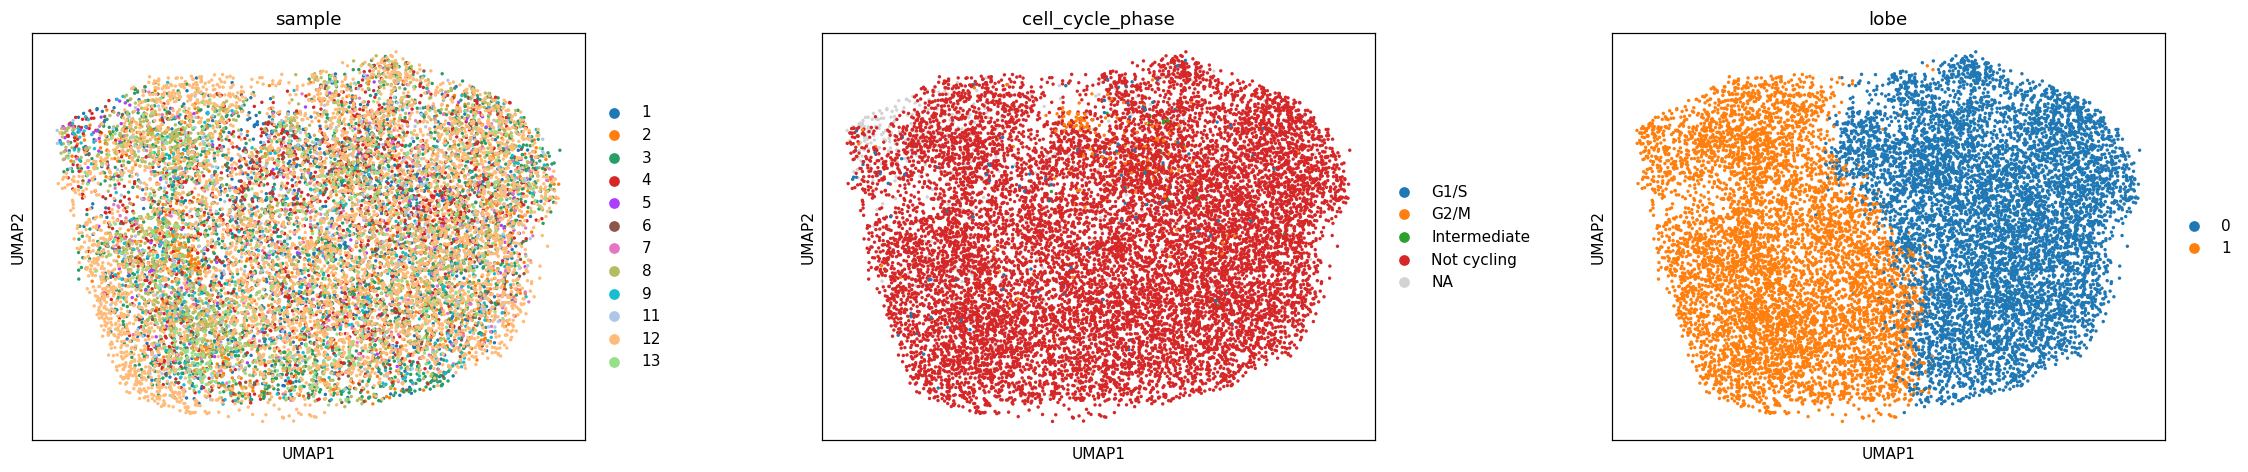

In [10]:
fig = sc.pl.umap(adata, color=['sample','cell_cycle_phase','lobe'],
                 size=20, wspace=.3, show=False)
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; lobes are two halves of the same cloud.')
print('Gate 1: sample-intermixed (iLISI plateau) AND one connected component -> GO')

In [11]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (14266, 21974)


### Deliverable — `samples.pdf`
House style: horizontal strip `(3.5, 1.5)`, `size=30`, coloured by `sample`. Intermixing across the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 14266


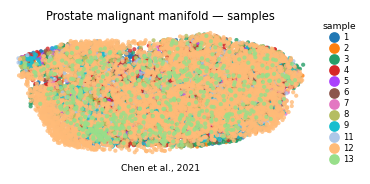

In [12]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Prostate malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Chen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])